# 02 — Evaluation protocol: features, time split and event-based metrics

**Goal**: fix, once for all methods, what a detector sees, which data it learns from, and how its alarms are scored.

**Key findings**

- Detectors work on a **regular one-minute grid** (79% of minutes valid) and on **18 backward-looking window features** (30 min and 2 h) that describe the compressor cycle: share of time loaded, cycle frequency, current, oil temperature, pressures.
- **Chronological split**: training on February 1 – April 10 (8.3 valid weeks, no reported failure), test on April 11 – September 1 (15.2 valid weeks, all four failures). The training period is **not clean** (four unreported sustained-load episodes, 2.8% of its time) and **drifts** (the compressor is loaded 6% of the time in February, 17% in March).
- **Event-based scoring**: alarms are merged into events, and each failure is scored as detected or missed, with its lead time. False alarms are counted per week. The threshold is calibrated on the training period only, with a budget of 1 alarm per week.
- **Chance level**: with detection windows of up to 64 h, a detector firing at random once a week would "detect" 0.7 of the 4 failures on average. Detections are therefore always read together with false alarms and lead times.
- **Protocol check**: the raw motor current detects **0/4** failures. Its 2-hour mean detects **4/4 with 0.9 false alarms per week**, flags failure 4 **13.7 h before** its reported start, and flags the other three within 2 h after their reported start. Windows, not single readings, carry the signal.
- **Drift costs alarms**: the 2-hour mean oil temperature could detect 4/4 with no false alarm, but only with a threshold in a narrow 75.4–76.2 °C band; the threshold calibrated on cooler winter data gives 1.4 false alarms per week.
- 3 of the 13 false alarms of the 2-hour mean current coincide with unreported sustained-load episodes, so false alarm rates in this benchmark are **upper bounds**.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

from metrobench import evaluation as ev
from metrobench.data import FAILURES, load, sustained_load_episodes
from metrobench.features import WINDOWS, load_features
from metrobench.plotstyle import FAILURE, GAP, INK_MUTED, SERIES, shade_failures, use_style

use_style()
FIG = Path("docs/figures")
grid, X = load_features()
episodes = sustained_load_episodes(load())
unreported = episodes[~episodes.reported]

## 1. A regular one-minute grid

Readings arrive every ~10 s with jitter and gaps. `metrobench.features.minute_grid` averages them on a regular one-minute grid, which is fine enough for a phenomenon that lasts hours. A minute is **valid** if it has readings and is not inside a frozen stretch longer than 30 minutes (notebook 01); invalid minutes stay in the grid as `NaN` so that the time axis remains regular. The grid also counts `load_starts`, the number of transitions to the loaded state, which measures how often the compressor cycles.

In [2]:
print(f"{len(grid):,} minutes, {grid.valid.mean():.1%} valid")
grid.loc["2020-03-10 10:00":"2020-03-10 10:09", ["Motor_current", "Oil_temperature", "DV_eletric", "load_starts", "valid"]].round(2)

306,960 minutes, 79.0% valid


,Motor_current,Oil_temperature,DV_eletric,load_starts,valid
2020-03-10 10:00:00,0.04,61.500000,0.00,0.0,True
2020-03-10 10:01:00,0.83,60.779999,0.17,1.0,True
2020-03-10 10:02:00,5.80,61.970001,1.00,0.0,True
2020-03-10 10:03:00,5.95,69.690002,1.00,0.0,True
2020-03-10 10:04:00,4.60,71.529999,0.33,0.0,True
2020-03-10 10:05:00,3.82,70.910004,0.00,0.0,True
2020-03-10 10:06:00,3.78,70.919998,0.00,0.0,True
2020-03-10 10:07:00,3.78,69.070000,0.00,0.0,True
2020-03-10 10:08:00,3.79,67.919998,0.00,0.0,True
2020-03-10 10:09:00,3.80,66.260002,0.00,0.0,True


## 2. Window features

An air leak is a collective anomaly: it is visible over a stretch of time, not in a single reading. Each feature summarises the **previous** 30 minutes or 2 hours (one or several compressor cycles) at every minute. Windows only look backwards, so a feature never uses the future. A feature is left `NaN` when less than 80% of its window is valid.

In [3]:
descriptions = {
    "load_share": "share of time under load (DV_eletric)",
    "load_starts": "loaded starts per hour (cycle frequency)",
    "current_mean": "mean motor current",
    "current_std": "motor current standard deviation (cycling amplitude)",
    "oil_mean": "mean oil temperature",
    "oil_max": "maximum oil temperature",
    "tp2_mean": "mean compressor outlet pressure",
    "reservoirs_mean": "mean reservoir pressure",
    "reservoirs_min": "minimum reservoir pressure",
}
pd.DataFrame({"description": descriptions, "windows": ", ".join(WINDOWS)}).rename_axis("feature")

,description,windows
feature,,
load_share,share of time under load (DV_eletric),"30min, 2h"
load_starts,loaded starts per hour (cycle frequency),"30min, 2h"
current_mean,mean motor current,"30min, 2h"
current_std,motor current standard deviation (cycling ampl...,"30min, 2h"
oil_mean,mean oil temperature,"30min, 2h"
oil_max,maximum oil temperature,"30min, 2h"
tp2_mean,mean compressor outlet pressure,"30min, 2h"
reservoirs_mean,mean reservoir pressure,"30min, 2h"
reservoirs_min,minimum reservoir pressure,"30min, 2h"


In [4]:
print(f"{X.shape[1]} features; all features available on {X.notna().all(axis=1).mean():.1%} of minutes")

18 features; all features available on 73.9% of minutes


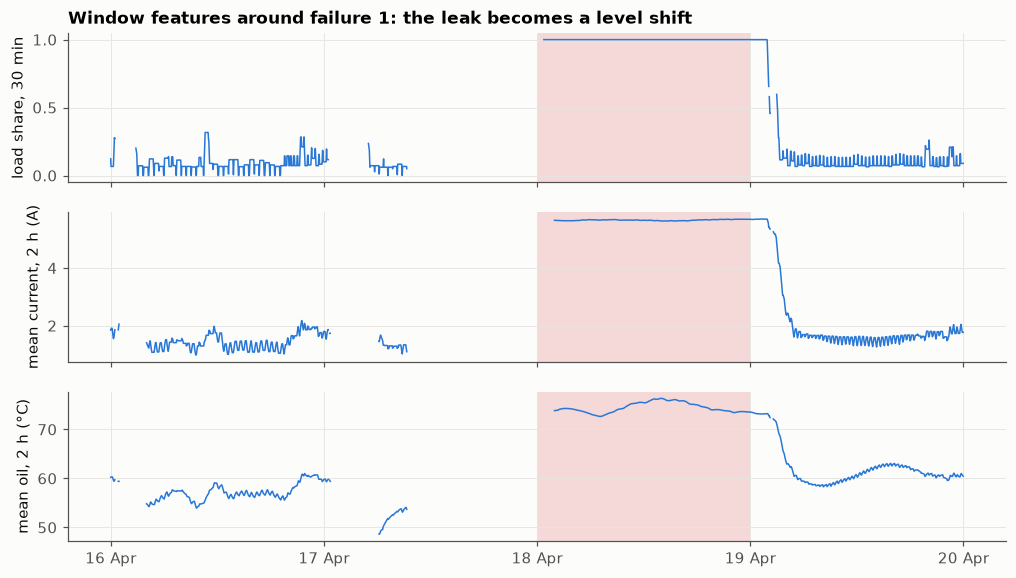

In [5]:
s, e = FAILURES.loc[1, ["start", "end"]]
w = X.loc[s - pd.Timedelta("2D"): e + pd.Timedelta("1D")]
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, col, label in zip(axes, ["load_share_30min", "current_mean_2h", "oil_mean_2h"],
                          ["load share, 30 min", "mean current, 2 h (A)", "mean oil, 2 h (°C)"]):
    ax.plot(w.index, w[col], color=SERIES[0], lw=1)
    shade_failures(ax, FAILURES.loc[[1]], label=False)
    ax.set_ylabel(label)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].set_title("Window features around failure 1: the leak becomes a level shift")
fig.savefig(FIG / "02_features_failure1.png")
plt.show()

## 3. Chronological split

In [6]:
train, test = ev.split(X)
def period_summary(frame, name):
    lo, hi = frame.index.min(), frame.index.max()
    unrep = unreported[(unreported.start >= lo) & (unreported.start <= hi)]
    return pd.Series({
        "from": lo.date(), "to": hi.date(),
        "valid weeks": round(frame.load_share_30min.notna().sum() / (7 * 24 * 60), 1),
        "reported failures": int(((FAILURES.start >= lo) & (FAILURES.start <= hi)).sum()),
        "unreported sustained-load episodes": len(unrep),
        "time in sustained load (%)": round(100 * (frame.load_share_30min >= 0.9).sum() / frame.load_share_30min.notna().sum(), 1),
        "mean load share (%)": round(100 * frame.load_share_30min.mean(), 1),
        "mean oil temperature (°C)": round(frame.oil_mean_30min.mean(), 1),
    }, name=name)
pd.concat([period_summary(train, "train"), period_summary(test, "test")], axis=1)

,train,test
from,2020-02-01,2020-04-11
to,2020-04-10,2020-09-01
valid weeks,8.3,15.2
reported failures,0,4
unreported sustained-load episodes,4,4
time in sustained load (%),2.8,5.1
mean load share (%),11.5,16.9
mean oil temperature (°C),59.5,64.4


- **Train** (February 1 – April 10): ten weeks without any reported failure, ending a week before failure 1. Methods learn "normal" behaviour from this period only, and their alarm threshold is calibrated on it.
- **Test** (April 11 – September 1): the four reported failures, scored once.

A random split would leak the future into training and, because consecutive minutes are nearly identical, inflate every score. Two properties of the training period matter for every method that follows:

- it is **not clean**: four unreported sustained-load episodes, the same signature as a leak, cover ~3% of its time. A detector that learns "normal" from it partly learns failures as normal;
- it **drifts**: the compressor works much less in February than from March onwards (below), and summer oil temperatures in the test period are higher. Some false alarms in the test period will come from this drift rather than from faults.

In [7]:
monthly = X[["load_share_30min", "oil_mean_30min"]].resample("MS").mean()
monthly["load_share_30min"] *= 100
monthly.index = monthly.index.strftime("%b")
monthly.round(1).rename(columns={"load_share_30min": "load share (%)", "oil_mean_30min": "oil (°C)"}).T

,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep
load share (%),6.1,17.0,15.8,17.9,21.2,15.2,12.6,8.0
oil (°C),56.4,62.2,59.6,62.1,66.1,67.0,65.2,58.1


## 4. Event-based scoring

A detector outputs one anomaly score per minute. Minutes with `score >= threshold` are alarms, and alarms less than 30 minutes apart are merged into **alarm events**. Scoring readings one by one would reward a detector for staying in alarm during a two-day failure and penalise it for alarming 10 minutes early. What matters to a maintenance team is whether each failure was flagged, how early, and how often it was disturbed for nothing.

Each alarm event is classified against the failure windows:

| Label | Rule | Counted as |
|---|---|---|
| **detection** | overlaps [failure start − 12 h, failure end] | the failure is detected; lead time = failure start − event start |
| **grace** | starts less than 24 h after a failure ends (the leak is often still there before the repair) | ignored |
| **false alarm** | any other event | false alarm |

An event that starts earlier than 12 h before a failure but lasts into its window still counts as a detection, with its full lead time: a persistent precursor is credited.

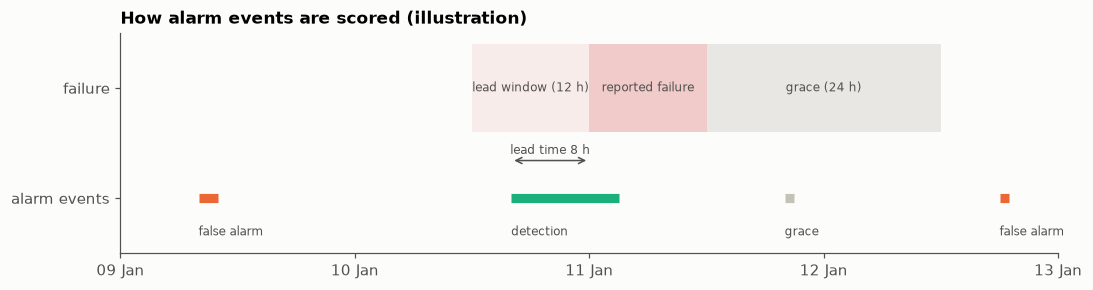

In [8]:
fig, ax = plt.subplots(figsize=(11, 2.6))
t0 = pd.Timestamp("2020-01-10 00:00")
fs, fe = t0 + pd.Timedelta("24h"), t0 + pd.Timedelta("36h")
ax.axvspan(fs - pd.Timedelta("12h"), fs, ymin=0.55, ymax=0.95, color=FAILURE, alpha=0.08, lw=0)
ax.axvspan(fs, fe, ymin=0.55, ymax=0.95, color=FAILURE, alpha=0.25, lw=0)
ax.axvspan(fe, fe + pd.Timedelta("24h"), ymin=0.55, ymax=0.95, color=GAP, alpha=0.35, lw=0)
for x0, x1, txt in [(fs - pd.Timedelta("12h"), fs, "lead window (12 h)"), (fs, fe, "reported failure"),
                    (fe, fe + pd.Timedelta("24h"), "grace (24 h)")]:
    ax.text(x0 + (x1 - x0) / 2, 0.75, txt, ha="center", va="center", fontsize=8, color=INK_MUTED)
alarms = [("2020-01-09 08:00", "2020-01-09 10:00", "false alarm"), ("2020-01-10 16:00", "2020-01-11 03:00", "detection"),
          ("2020-01-11 20:00", "2020-01-11 21:00", "grace"), ("2020-01-12 18:00", "2020-01-12 19:00", "false alarm")]
colors = {"detection": SERIES[2], "grace": GAP, "false alarm": SERIES[1]}
for a, b, lab in alarms:
    ax.plot([pd.Timestamp(a), pd.Timestamp(b)], [0.25, 0.25], color=colors[lab], lw=6, solid_capstyle="butt")
    ax.text(pd.Timestamp(a), 0.08, lab, fontsize=8, color=INK_MUTED)
ax.annotate("", xy=(pd.Timestamp("2020-01-10 16:00"), 0.42), xytext=(fs, 0.42),
            arrowprops=dict(arrowstyle="<->", color=INK_MUTED, lw=1))
ax.text(pd.Timestamp("2020-01-10 20:00"), 0.45, "lead time 8 h", ha="center", fontsize=8, color=INK_MUTED)
ax.set_ylim(0, 1)
ax.set_yticks([0.25, 0.75], ["alarm events", "failure"])
ax.grid(False)
ax.set_xlim(pd.Timestamp("2020-01-09 00:00"), pd.Timestamp("2020-01-13 00:00"))
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title("How alarm events are scored (illustration)")
fig.savefig(FIG / "02_scoring_rules.png")
plt.show()

### Threshold: calibrated on training data

A method is compared at two operating points:

1. **Calibrated** (deployable): the threshold is the lowest one that keeps the *training* period within a budget of **1 alarm event per week** and 5% of time in alarm. No test label is used. This is the number a maintenance team would actually get.
2. **Best at budget** (optimistic, for comparison only): the threshold is swept on the test period and the best point with at most 1 false alarm per week is reported. It shows what a method could achieve with a perfectly tuned threshold, so it separates "bad scores" from "badly placed threshold".

### Chance level

Detection windows are long (failure 3 lasts 52 h), so a detector that fires at random can still "detect" failures. The expected number of chance detections out of four, for alarms fired at random at a given rate:

In [9]:
pd.DataFrame({"random alarms per week": [0.5, 1, 2, 5],
              "expected chance detections (of 4)": [round(ev.chance_detections(r), 2) for r in [0.5, 1, 2, 5]]})

,random alarms per week,expected chance detections (of 4)
0,0.5,0.38
1,1.0,0.71
2,2.0,1.26
3,5.0,2.32


At 1 false alarm per week, a useless detector detects ~0.7 failures on average. Detections must therefore be read together with false alarms and lead times.

## 5. Protocol check: single readings vs windows

The protocol is tried on four single-signal scores, the simplest possible detectors: the raw motor current and oil temperature (one reading per minute), and their window counterparts.

In [10]:
candidates = {
    "Motor_current (raw minute)": grid.Motor_current,
    "Oil_temperature (raw minute)": grid.Oil_temperature,
    "current_mean_2h": X.current_mean_2h,
    "oil_mean_2h": X.oil_mean_2h,
}
rows, results, curves = [], {}, {}
for name, score in candidates.items():
    score_train, score_test = ev.split(score)
    threshold = ev.calibrate(score_train)
    r = ev.evaluate(score_test, threshold)
    curve = ev.operating_curve(score_test)
    best = ev.best_at_budget(curve)
    results[name], curves[name] = r, curve
    rows.append({
        "score": name,
        "threshold": round(threshold, 2),
        "detected": f"{r['detected']}/{r['failures']}",
        "median lead (h)": round(r["median_lead_h"], 1),
        "false alarms / week": round(r["false_alarms_per_week"], 2),
        "time in alarm (%)": round(r["alarm_share_%"], 1),
        "best at budget: detected": int(best["detected"]) if len(best) else 0,
    })
check = pd.DataFrame(rows).set_index("score")
check

,threshold,detected,median lead (h),false alarms / week,time in alarm (%),best at budget: detected
score,,,,,,
Motor_current (raw minute),6.23,0/4,NaN,0.45,0.0,0
Oil_temperature (raw minute),75.34,4/4,-0.4,3.59,2.2,1
current_mean_2h,3.62,4/4,-0.8,0.90,6.3,4
oil_mean_2h,69.46,4/4,-0.8,1.38,9.0,4


In [11]:
pd.DataFrame({name: pd.Series(r["lead_hours"]).round(1) for name, r in results.items()}).reindex(FAILURES.index).rename_axis("failure")

,Motor_current (raw minute),Oil_temperature (raw minute),current_mean_2h,oil_mean_2h
failure,,,,
1,NaN,-8.8,-2.0,-2.0
2,NaN,-0.7,-0.8,-0.9
3,NaN,-0.2,-0.8,-0.7
4,NaN,7.6,13.7,14.1


Lead times per failure (hours; positive = before the reported start, empty = missed).

The operating curves below show, for each false-alarm budget on the test period, the most failures a score can detect with the best possible threshold. They are optimistic by construction, but they compare the scores themselves, independently of the calibration.

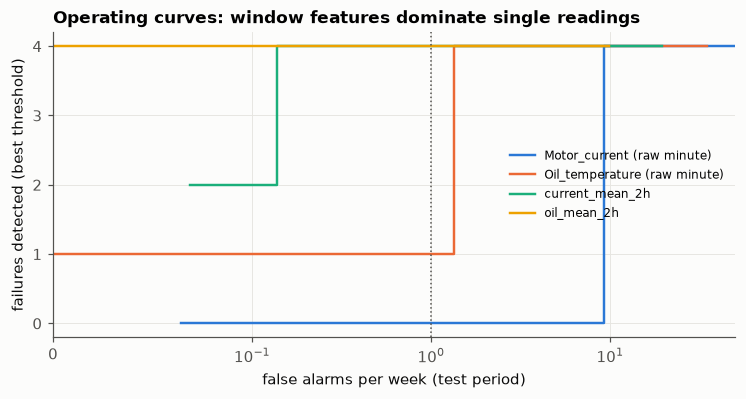

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (name, curve) in enumerate(curves.items()):
    c = curve.sort_values("false_alarms_per_week")
    envelope = c.detected.cummax()  # best result reachable within each false-alarm budget
    ax.step(c.false_alarms_per_week, envelope, where="post", color=SERIES[k], label=name, lw=1.6)
ax.axvline(1, color=INK_MUTED, ls=":", lw=1)
ax.set_xscale("symlog", linthresh=0.1)
ax.set_xlim(0, 50)
ax.set_xlabel("false alarms per week (test period)")
ax.set_ylabel("failures detected (best threshold)")
ax.set_yticks(range(5))
ax.legend(loc="center right", fontsize=8)
ax.set_title("Operating curves: window features dominate single readings")
fig.savefig(FIG / "02_operating_curves.png")
plt.show()

With a well-placed threshold, the 2-hour mean oil temperature separates the four failures from everything else in the test period: 4/4 with **no false alarm**, but only for thresholds between 75.4 and 76.2 °C. The threshold calibrated on training data, 69.5 °C, sits well below that band because training covers February–April, when the oil runs ~5 °C cooler than in summer. The gap between the calibrated and the best result is the **cost of drift**, and closing it (seasonally adjusted features, recalibration) is part of what later methods are judged on.

## 6. Where do the false alarms come from?

In [13]:
events = results["current_mean_2h"]["events"]
fa = events[events.label == "false alarm"].copy()
fa["unreported_sustained_load"] = ev.overlaps(fa, unreported)
fa["duration"] = (fa.end - fa.start).dt.round("1min")
fa

,start,end,label,unreported_sustained_load,duration
0,2020-04-12 12:48:00,2020-04-13 00:46:00,false alarm,True,0 days 11:58:00
2,2020-05-13 14:57:00,2020-05-14 01:18:00,false alarm,True,0 days 10:21:00
3,2020-05-19 10:39:00,2020-05-19 12:21:00,false alarm,False,0 days 01:42:00
4,2020-05-19 23:01:00,2020-05-20 19:48:00,false alarm,True,0 days 20:47:00
6,2020-06-01 15:22:00,2020-06-01 17:00:00,false alarm,False,0 days 01:38:00
7,2020-06-03 11:07:00,2020-06-03 12:15:00,false alarm,False,0 days 01:08:00
11,2020-07-08 18:24:00,2020-07-08 20:33:00,false alarm,False,0 days 02:09:00
12,2020-07-08 22:26:00,2020-07-08 23:20:00,false alarm,False,0 days 00:54:00
13,2020-07-13 07:04:00,2020-07-13 09:39:00,false alarm,False,0 days 02:35:00
15,2020-07-16 19:27:00,2020-07-16 21:15:00,false alarm,False,0 days 01:48:00


In [14]:
print(f"{fa.unreported_sustained_load.sum()} of {len(fa)} false alarms of current_mean_2h overlap an unreported sustained-load episode")

3 of 13 false alarms of current_mean_2h overlap an unreported sustained-load episode


Three of the 13 false alarms are the unreported sustained-load episodes of April 12, May 13 and May 19–20: from the machine's point of view they look like leaks, so the false alarm rate is an upper bound. Three more (July 16–17) start shortly after the 24-hour grace period that follows failure 4, possibly after-effects of the same leak or of its repair. The grace period is not stretched after the fact to absorb them, since that would tune the protocol on the test set. The remaining alarms are short (20 min to 4 h) periods of higher load, operating variations that a single-feature detector cannot tell apart from a fault.

## 7. Protocol summary

| Decision | Choice |
|---|---|
| Time resolution | one-minute grid; invalid minutes (gaps, frozen readings) kept as `NaN` |
| Inputs | 18 backward-looking window features (30 min, 2 h), or the minute grid for sequence models |
| Training data | February 1 – April 10, no reported failure (contains unreported sustained-load episodes) |
| Test data | April 11 – September 1, four reported failures |
| Threshold | lowest threshold with ≤ 1 alarm event per week and ≤ 5% of time in alarm on the training period |
| Scoring | alarm events (merged within 30 min); detection window [start − 12 h, end]; 24 h grace after a failure |
| Reported metrics | failures detected, lead time per failure, false alarms per week, time in alarm; plus best result at ≤ 1 false alarm per week |
| Reference | chance level, ~0.7 detections at 1 random alarm per week |

The next notebooks plug detectors into this protocol, starting with statistical baselines.